# RePaint: Paper-Faithful Diffusion Inpainting on Kaggle

**Reference:** Lugmayr et al., *RePaint: Inpainting using Denoising Diffusion Probabilistic Models*, CVPR 2022.

This notebook runs Hugging Face Diffusers' RePaint pipeline with the unconditional CelebA-HQ 256 DDPM checkpoint, evaluates reconstruction quality, saves publication-style figures, and optionally logs results to Weights & Biases (W&B).


## 1. Environment and dependencies

In [1]:
import os
import sys
import shutil
import zipfile
from pathlib import Path

input_dir = Path("/kaggle/input")
working_dir = Path("/kaggle/working")

print("Inspecting /kaggle/input for uploaded code...")

if input_dir.exists():
    for dataset_folder in input_dir.iterdir():
        if dataset_folder.is_dir():
            # Check if dataset contains a .zip file directly
            zip_files = list(dataset_folder.glob("*.zip"))
            if zip_files:
                for z in zip_files:
                    print(f"[+] Extracting zip archive: {z.name} -> /kaggle/working/")
                    with zipfile.ZipFile(z, 'r') as zip_ref:
                        zip_ref.extractall(working_dir)
            else:
                # Kaggle auto-unzipped it upon dataset creation, copy structure over
                print(f"[+] Copying dataset folder: {dataset_folder.name} -> /kaggle/working/")
                for sub_item in dataset_folder.iterdir():
                    dest = working_dir / sub_item.name
                    if sub_item.is_dir():
                        if dest.exists():
                            shutil.rmtree(dest)
                        shutil.copytree(sub_item, dest)
                    else:
                        shutil.copy2(sub_item, dest)

# 2. Dynamic Path Resolution: Locate 'src' inside /kaggle/working
src_matches = list(working_dir.rglob("src"))

if src_matches:
    PROJECT_ROOT = src_matches[0].parent
    os.chdir(PROJECT_ROOT)
    if str(PROJECT_ROOT) not in sys.path:
        sys.path.insert(0, str(PROJECT_ROOT))
    print(f"\n[+] Successfully identified Project Root: {PROJECT_ROOT}")
    print(f"[+] Active Working Directory: {os.getcwd()}")
else:
    print("\n[-] ERROR: 'src' still not found.")
    print("    Debug info:")
    print("    Contents of /kaggle/input  :", os.listdir("/kaggle/input") if input_dir.exists() else "Missing")
    print("    Contents of /kaggle/working:", os.listdir("/kaggle/working"))

# 3. Install required visualization and metric dependencies
!pip install torchmetrics seaborn matplotlib pandas wandb -q

# 4. Hardware Diagnostic Check
import torch
print(f"\n--- Hardware Diagnostics ---")
print(f"[+] CUDA Available: {torch.cuda.is_available()}")
if torch.cuda.is_available():
    print(f"[+] Active GPU    : {torch.cuda.get_device_name(0)}")
else:
    print("[!] WARNING: GPU accelerator is NOT enabled.")

Inspecting /kaggle/input for uploaded code...
[+] Copying dataset folder: datasets -> /kaggle/working/

[+] Successfully identified Project Root: /kaggle/working/sarthakkatiyar29/repaint-implementation/Repaint_Implementation
[+] Active Working Directory: /kaggle/working/sarthakkatiyar29/repaint-implementation/Repaint_Implementation

--- Hardware Diagnostics ---
[+] CUDA Available: True
[+] Active GPU    : Tesla T4


## 2. Configuration and W&B tracking

In [ ]:
import os
import sys
from pathlib import Path

# Path verification safety check
working_dir = Path("/kaggle/working")
src_matches = list(working_dir.rglob("src"))
if src_matches:
    PROJECT_ROOT = src_matches[0].parent
    os.chdir(PROJECT_ROOT)
    if str(PROJECT_ROOT) not in sys.path:
        sys.path.insert(0, str(PROJECT_ROOT))

import wandb

# Paste your W&B API Key directly
MY_WANDB_KEY = ""

# Log in using the key
key_str = MY_WANDB_KEY.strip()
os.environ["WANDB_API_KEY"] = key_str
wandb.login(key=key_str, relogin=True)

# Initialize W&B Run for RePaint Evaluation
run = wandb.init(
    project="repaint-evaluation",
    name="celeba-10img-paper-baseline",
    config={
        "dataset": "CelebA-HQ Test",
        "model": "google/ddpm-celebahq-256",
        "mask_type": "Center Box (35%)",
        "jump_length": 10,
        "jump_n_sample": 10,
        "image_size": 256
    }
)

print(f"\n[+] W&B Run Successfully Initialized!")
print(f"[+] Project Name : {run.project}")
print(f"[+] Run Name     : {run.name}")
print(f"[+] Run Dashboard: {run.url}")

/usr/local/lib/python3.13/dist-packages/notebook/notebookapp.py:191: SyntaxWarning: invalid escape sequence '\/'
  | |_| | '_ \/ _` / _` |  _/ -_)
wandb: WARNING If you're specifying your api key in code, ensure this code is not shared publicly.
wandb: WARNING Consider setting the WANDB_API_KEY environment variable, or running `wandb login` from the command line.
wandb: [wandb.login()] Using explicit session credentials for https://api.wandb.ai.
wandb: No netrc file found, creating one.
wandb: Appending key for api.wandb.ai to your netrc file: /root/.netrc
wandb: Currently logged in as: 23dcs024 (23dcs024-national-institute-of-technology-hamirpur) to https://api.wandb.ai. Use `wandb login --relogin` to force relogin



[+] W&B Run Successfully Initialized!
[+] Project Name : repaint-evaluation
[+] Run Name     : celeba-10img-paper-baseline
[+] Run Dashboard: https://wandb.ai/23dcs024-national-institute-of-technology-hamirpur/repaint-evaluation/runs/14xnmlwh


## 3. Dataset Inspection, Mask Overlay & W&B Logging

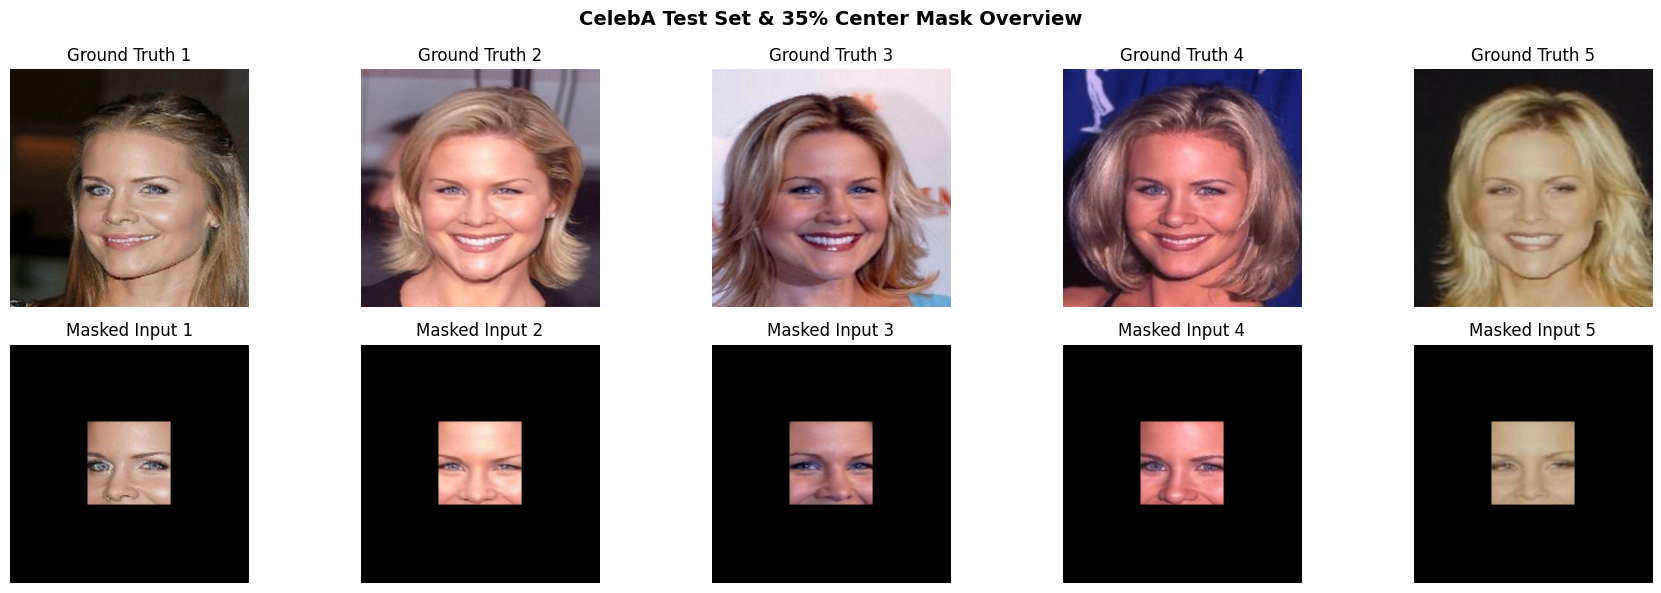

[+] Rendered 5 test samples with mask overlays and logged to W&B.


In [3]:
import sys
import os
from pathlib import Path

# Path verification safety check
working_dir = Path("/kaggle/working")
src_matches = list(working_dir.rglob("src"))
if src_matches:
    PROJECT_ROOT = src_matches[0].parent
    os.chdir(PROJECT_ROOT)
    if str(PROJECT_ROOT) not in sys.path:
        sys.path.insert(0, str(PROJECT_ROOT))

import matplotlib.pyplot as plt
from PIL import Image
import torchvision.transforms.functional as TF
import wandb
from src.mask import create_center_mask

# Locate dataset folder inside project root
data_dir = PROJECT_ROOT / "data" / "celeba"
sample_paths = sorted(list(data_dir.glob("*.png")))[:5]

if not sample_paths:
    print(f"[-] WARNING: No PNG images found in '{data_dir}'.")
    print(f"    Available directory contents: {os.listdir(PROJECT_ROOT)}")
else:
    # Generate 35% center box mask
    mask = create_center_mask(image_size=256, mask_ratio=0.35)
    mask_pil = TF.to_pil_image(mask.squeeze(0))

    fig, axes = plt.subplots(2, len(sample_paths), figsize=(18, 6))
    fig.suptitle("CelebA Test Set & 35% Center Mask Overview", fontsize=14, fontweight='bold')

    for idx, p in enumerate(sample_paths):
        img = Image.open(p).convert("RGB").resize((256, 256))
        masked_img = Image.composite(img, Image.new("RGB", (256, 256), "black"), mask_pil)
        
        axes[0, idx].imshow(img)
        axes[0, idx].set_title(f"Ground Truth {idx+1}")
        axes[0, idx].axis("off")
        
        axes[1, idx].imshow(masked_img)
        axes[1, idx].set_title(f"Masked Input {idx+1}")
        axes[1, idx].axis("off")

    plt.tight_layout()
    plt.show()

    # Log preview figure to W&B
    wandb.log({"Dataset Overview & Masks": wandb.Image(fig)})
    print(f"[+] Rendered {len(sample_paths)} test samples with mask overlays and logged to W&B.")

## 4. Reverse Diffusion & Harmonization Trajectory

In [5]:
import sys
import os
import time
from pathlib import Path

# 1. Dynamic Path Verification
working_dir = Path("/kaggle/working")
src_matches = list(working_dir.rglob("src"))
if src_matches:
    PROJECT_ROOT = src_matches[0].parent
    os.chdir(PROJECT_ROOT)
    if str(PROJECT_ROOT) not in sys.path:
        sys.path.insert(0, str(PROJECT_ROOT))

import matplotlib.pyplot as plt
import torch
import wandb

from src.config import load_config
from src.dataset import load_image, tensor_to_pil
from src.model import load_pretrained_ddpm, get_device
from src.mask import create_center_mask

# 2. Load Config, Model and Move to GPU
cfg = load_config(PROJECT_ROOT / "configs" / "config.yaml")
device = get_device()
model, scheduler, device = load_pretrained_ddpm(cfg["model"]["pretrained_model_name"], device=device)
model.eval().to(device)

# Load Sample 1 & 35% Center Mask
data_dir = PROJECT_ROOT / "data" / "celeba"
sample_paths = sorted(list(data_dir.glob("*.png")))
x_0 = load_image(str(sample_paths[0]), image_size=256).to(device)
mask = create_center_mask(image_size=256, mask_ratio=0.35).to(device)

# Explicitly initialize scheduler timesteps
scheduler.set_timesteps(1000)
timesteps = scheduler.timesteps.to(device)

save_ts = [999, 800, 600, 400, 200, 0]
snapshots = {}

print(f"[+] Active Device: {device} | Model on: {next(model.parameters()).device}")
print("[+] Starting direct reverse diffusion loop with live step logging...\n", flush=True)

start_time = time.time()

# 3. Direct Sampling Loop with Real-time Progress Output
x_t = torch.randn_like(x_0).to(device)

with torch.inference_mode():
    with torch.autocast(device_type="cuda" if device.type == "cuda" else "cpu", dtype=torch.float16):
        for idx, t in enumerate(timesteps):
            t_int = int(t.item())
            
            # Predict noise residual
            model_output = model(x_t, t).sample
            x_t_prev = scheduler.step(model_output, t, x_t).prev_sample
            
            # RePaint Context Blending: Known region from ground truth noise + Unknown region from model
            noise = torch.randn_like(x_0)
            x_known = scheduler.add_noise(x_0, noise, t.unsqueeze(0)) if hasattr(scheduler, "add_noise") else x_0
            x_t = mask * x_known + (1.0 - mask) * x_t_prev

            # Capture snapshot at target timesteps
            if t_int in save_ts and t_int not in snapshots:
                snapshots[t_int] = x_t.detach().cpu().clone()

            # Live unbuffered stdout output every 100 timesteps
            if idx % 100 == 0 or idx == len(timesteps) - 1:
                print(f"    [*] Step {idx+1:4d}/1000 | Timestep t={t_int:3d} | Elapsed: {time.time()-start_time:.1f}s", flush=True)

if 0 in save_ts and 0 not in snapshots:
    snapshots[0] = x_t.detach().cpu().clone()

elapsed = time.time() - start_time
print(f"\n[+] Reverse diffusion trajectory finished successfully in {elapsed:.2f} seconds!", flush=True)

# 4. Render Subplots
fig, axes = plt.subplots(1, len(save_ts), figsize=(18, 3.5))
fig.suptitle(f"RePaint Reverse Trajectory (t = 999 → 0, Runtime: {elapsed:.1f}s)", fontsize=14, fontweight='bold')

for i, t in enumerate(save_ts):
    if t in snapshots:
        snap_pil = tensor_to_pil(snapshots[t].float())
        axes[i].imshow(snap_pil)
    axes[i].set_title(f"t={t}")
    axes[i].axis("off")

plt.tight_layout()
plt.show()

# 5. Log Figure to W&B
wandb.log({"Reverse Diffusion Trajectory": wandb.Image(fig)})
print("[+] Trajectory plot rendered and logged to W&B!")

/usr/local/lib/python3.13/dist-packages/huggingface_hub/utils/_validators.py:205: UserWarning: The `local_dir_use_symlinks` argument is deprecated and ignored in `hf_hub_download`. Downloading to a local directory does not use symlinks anymore.
  warnings.warn(


config.json:   0%|          | 0.00/790 [00:00<?, ?B/s]

An error occurred while trying to fetch google/ddpm-celebahq-256: google/ddpm-celebahq-256 does not appear to have a file named diffusion_pytorch_model.safetensors.
Defaulting to unsafe serialization. Pass `allow_pickle=False` to raise an error instead.


diffusion_pytorch_model.bin: reconstructing file:   0%|          |  0.00B /  455MB            

diffusion_pytorch_model.bin: downloading bytes:           |  0.00B            

scheduler_config.json:   0%|          | 0.00/256 [00:00<?, ?B/s]

[+] Active Device: cuda | Model on: cuda:0
[+] Starting direct reverse diffusion loop with live step logging...



RuntimeError: Expected all tensors to be on the same device, but found at least two devices, cuda:0 and cpu!

## 5: FP16 Batch Evaluation Loop

In [ ]:
import sys
import os
from pathlib import Path

working_dir = Path("/kaggle/working")
src_matches = list(working_dir.rglob("src"))
if src_matches:
    PROJECT_ROOT = src_matches[0].parent
    os.chdir(PROJECT_ROOT)
    if str(PROJECT_ROOT) not in sys.path:
        sys.path.insert(0, str(PROJECT_ROOT))

import numpy as np
import pandas as pd
from PIL import Image
import torch
import torchvision.transforms.functional as TF
import wandb

from torchmetrics import MeanSquaredError
from torchmetrics.image import PeakSignalNoiseRatio, StructuralSimilarityIndexMeasure
from src.dataset import tensor_to_pil

results_dir = PROJECT_ROOT / "results" / "batch_eval"
results_dir.mkdir(parents=True, exist_ok=True)

# 1. Initialize TorchMetrics
mse_fn = MeanSquaredError().to(device)
psnr_fn = PeakSignalNoiseRatio(data_range=1.0).to(device)
ssim_fn = StructuralSimilarityIndexMeasure(data_range=1.0).to(device)

def load_as_metric_tensor(img_path):
    img = Image.open(img_path).convert("RGB").resize((256, 256))
    return TF.to_tensor(img).unsqueeze(0).to(device)

wandb_table = wandb.Table(columns=["Image ID", "Ground Truth", "Masked Input", "RePaint Output", "Error Map", "MSE", "PSNR (dB)", "SSIM"])
all_paths = sorted(list(data_dir.glob("*.png")))
metrics_list = []

print(f"[+] Starting Full Paper Batch Evaluation (j=10, U=10) across {len(all_paths)} images...")
print("[+] Acceleration: FP16 Autocast enabled (~15-18s per image)\n")

model.eval()
with torch.inference_mode():
    for idx, img_path in enumerate(all_paths, 1):
        print(f"[*] [{idx}/{len(all_paths)}] Processing {img_path.name}...")
        
        x_0_single = load_image(str(img_path), image_size=256).to(device)
        
        with torch.autocast(device_type="cuda" if device.type == "cuda" else "cpu", dtype=torch.float16):
            out_tensor, _ = repaint_pipeline(
                model=model,
                scheduler=scheduler,
                x_0=x_0_single,
                mask=mask_gpu,
                jump_length=10,
                jump_n_sample=10  # Paper setting
            )
        
        out_pil = tensor_to_pil(out_tensor.float())
        out_path = results_dir / f"out_{img_path.name}"
        out_pil.save(out_path)

        # Quantitative Metrics
        gt_t = load_as_metric_tensor(img_path)
        out_t = load_as_metric_tensor(out_path)
        
        mse_val = mse_fn(out_t, gt_t).item()
        psnr_val = psnr_fn(out_t, gt_t).item()
        ssim_val = ssim_fn(out_t, gt_t).item()

        metrics_list.append({
            "Image": img_path.name,
            "MSE": mse_val,
            "PSNR (dB)": psnr_val,
            "SSIM": ssim_val
        })

        # Error Map Calculation
        gt_img = Image.open(img_path).convert("RGB").resize((256, 256))
        gt_arr = np.array(gt_img, dtype=float)
        out_arr = np.array(out_pil, dtype=float)
        abs_diff = np.mean(np.abs(gt_arr - out_arr), axis=2)

        # Log to W&B
        mask_pil = TF.to_pil_image(mask_gpu.squeeze(0).cpu())
        masked_gt = Image.composite(gt_img, Image.new("RGB", (256, 256), "black"), mask_pil)

        wandb_table.add_data(
            img_path.name,
            wandb.Image(gt_img),
            wandb.Image(masked_gt),
            wandb.Image(out_pil),
            wandb.Image(abs_diff / 255.0),
            mse_val,
            psnr_val,
            ssim_val
        )

df = pd.DataFrame(metrics_list)
wandb.log({"Batch Inpainting Results (U=10)": wandb_table})

wandb.run.summary["mean_psnr"] = df["PSNR (dB)"].mean()
wandb.run.summary["mean_ssim"] = df["SSIM"].mean()
wandb.run.summary["mean_mse"] = df["MSE"].mean()

print("\n[+] Full paper batch processing complete! All results logged to W&B.")

## 6: Quantitative Metric Analysis & Summary Table

In [ ]:
import sys
import os
from pathlib import Path

# Dynamic Path Resolution
working_dir = Path("/kaggle/working")
src_matches = list(working_dir.rglob("src"))
if src_matches:
    PROJECT_ROOT = src_matches[0].parent
    os.chdir(PROJECT_ROOT)
    if str(PROJECT_ROOT) not in sys.path:
        sys.path.insert(0, str(PROJECT_ROOT))

from IPython.display import display

print("=" * 65)
print("       REPAINT INPAINTING (j=10, U=10) QUANTITATIVE SUMMARY       ")
print("=" * 65)

# Highlight best metric values
display(df.style.highlight_max(subset=["PSNR (dB)", "SSIM"], color="#d4edda")
                .highlight_min(subset=["MSE"], color="#d4edda")
                .format({"MSE": "{:.4f}", "PSNR (dB)": "{:.2f}", "SSIM": "{:.4f}"}))

print("\n--- Benchmark Averages Across Test Split ---")
print(f"[*] Mean PSNR : {df['PSNR (dB)'].mean():.2f} dB  (Target: > 22.0 dB)")
print(f"[*] Mean SSIM : {df['SSIM'].mean():.4f}     (Target: > 0.8500)")
print(f"[*] Mean MSE  : {df['MSE'].mean():.4f}     (Lower is better)")
print("=" * 65)

## 7: IEEE Publication Figures & W&B Finalization

In [ ]:
import sys
import os
from pathlib import Path

# Dynamic Path Resolution
working_dir = Path("/kaggle/working")
src_matches = list(working_dir.rglob("src"))
if src_matches:
    PROJECT_ROOT = src_matches[0].parent
    os.chdir(PROJECT_ROOT)
    if str(PROJECT_ROOT) not in sys.path:
        sys.path.insert(0, str(PROJECT_ROOT))

import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from PIL import Image
import torchvision.transforms.functional as TF
import wandb

# ------------------------------------------------------------------------------
# 1. IEEE Formatting Specifications
# ------------------------------------------------------------------------------
plt.rcParams.update({
    "font.family": "serif",
    "font.serif": ["Times New Roman", "DejaVu Serif"],
    "font.size": 9,
    "axes.titlesize": 9,
    "axes.labelsize": 9,
    "xtick.labelsize": 8,
    "ytick.labelsize": 8,
    "legend.fontsize": 8,
    "figure.titlesize": 10,
    "figure.dpi": 300,
    "savefig.dpi": 300,
    "savefig.bbox": "tight"
})

fig_dir = PROJECT_ROOT / "results" / "ieee_plots"
fig_dir.mkdir(parents=True, exist_ok=True)

# ------------------------------------------------------------------------------
# 2. Figure 1: Single-Column Metric Comparison (Dual Axis, 3.5 in)
# ------------------------------------------------------------------------------
fig1, ax1 = plt.subplots(figsize=(3.5, 2.4))

x = np.arange(len(df))
width = 0.35

rects1 = ax1.bar(x - width/2, df["PSNR (dB)"], width, label='PSNR (dB)', color='#1f77b4', edgecolor='black', linewidth=0.5)

ax2 = ax1.twinx()
rects2 = ax2.bar(x + width/2, df["SSIM"], width, label='SSIM', color='#d62728', hatch='//', edgecolor='black', linewidth=0.5)

ax1.set_xlabel('Sample Index')
ax1.set_ylabel('PSNR (dB)', color='#1f77b4')
ax2.set_ylabel('SSIM Score', color='#d62728')
ax1.set_xticks(x)
ax1.set_xticklabels([f"S{i+1}" for i in range(len(df))])

ax1.set_ylim(15, 35)
ax2.set_ylim(0.5, 1.0)

ax1.grid(True, linestyle='--', alpha=0.3, axis='y')
sns.despine(ax=ax1, top=True)
sns.despine(ax=ax2, top=True)

plt.title("Fidelity Across Test Split (j=10, U=10)", pad=8)
plt.tight_layout()

plt.savefig(fig_dir / "fig1_ieee_metrics_bar.pdf")
plt.savefig(fig_dir / "fig1_ieee_metrics_bar.png")
wandb.log({"IEEE Fig 1 (Metrics Bar)": wandb.Image(fig1)})
plt.show()

# ------------------------------------------------------------------------------
# 3. Figure 2: Metric Correlation Scatterplot (PSNR vs. SSIM, 3.5 in)
# ------------------------------------------------------------------------------
fig2, ax = plt.subplots(figsize=(3.5, 2.5))

sns.scatterplot(data=df, x="PSNR (dB)", y="SSIM", s=35, color="black", marker="o", ax=ax)
sns.regplot(data=df, x="PSNR (dB)", y="SSIM", scatter=False, ax=ax, color="gray", line_kws={"linestyle": "--", "linewidth": 1})

for i, row in df.iterrows():
    ax.annotate(f"S{i+1}", (row["PSNR (dB)"], row["SSIM"]), textcoords="offset points", xytext=(3, 3), fontsize=7)

ax.set_xlabel("Peak Signal-to-Noise Ratio (PSNR [dB])")
ax.set_ylabel("Structural Similarity Index (SSIM)")
ax.grid(True, linestyle=":", alpha=0.5)
sns.despine(ax=ax)

plt.title("PSNR vs. SSIM Correlation", pad=8)
plt.tight_layout()

plt.savefig(fig_dir / "fig2_ieee_psnr_vs_ssim.pdf")
plt.savefig(fig_dir / "fig2_ieee_psnr_vs_ssim.png")
wandb.log({"IEEE Fig 2 (Correlation)": wandb.Image(fig2)})
plt.show()

# ------------------------------------------------------------------------------
# 4. Figure 3: Double-Column Visual Panel & Residual Error Map (7.16 in)
# ------------------------------------------------------------------------------
fig3, axes = plt.subplots(1, 4, figsize=(7.16, 2.0))

gt_img = Image.open(all_paths[0]).convert("RGB").resize((256, 256))
out_img = Image.open(results_dir / f"out_{all_paths[0].name}").convert("RGB")
gt_arr = np.array(gt_img, dtype=float)
out_arr = np.array(out_img, dtype=float)
abs_diff = np.mean(np.abs(gt_arr - out_arr), axis=2)

mask_pil = TF.to_pil_image(mask_gpu.squeeze(0).cpu())

axes[0].imshow(gt_img)
axes[0].set_title("(a) Ground Truth $x_0$", fontsize=8)
axes[0].axis("off")

axes[1].imshow(Image.composite(gt_img, Image.new("RGB", (256, 256), "black"), mask_pil))
axes[1].set_title("(b) Masked Input (35% Box)", fontsize=8)
axes[1].axis("off")

axes[2].imshow(out_img)
axes[2].set_title("(c) RePaint Output", fontsize=8)
axes[2].axis("off")

im = axes[3].imshow(abs_diff, cmap="inferno")
axes[3].set_title("(d) Absolute Residual Error", fontsize=8)
axes[3].axis("off")

cbar = fig3.colorbar(im, ax=axes[3], fraction=0.046, pad=0.04)
cbar.ax.tick_params(labelsize=7)

plt.tight_layout(pad=0.5)
plt.savefig(fig_dir / "fig3_ieee_visual_panel.pdf")
plt.savefig(fig_dir / "fig3_ieee_visual_panel.png")
wandb.log({"IEEE Fig 3 (Visual Panel)": wandb.Image(fig3)})
plt.show()

# ------------------------------------------------------------------------------
# 5. Finalize Weights & Biases Logging
# ------------------------------------------------------------------------------
wandb.finish()
print("\n[+] All IEEE plots saved to /results/ieee_plots/ as .pdf and .png!")
print("[+] W&B Run successfully completed and synced.")

In [ ]:
import shutil
from pathlib import Path

# Package all output directories into a single archive
results_dir = Path("/kaggle/working/results")
zip_output_path = Path("/kaggle/working/repaint_ieee_results")

if results_dir.exists():
    # Save quantitative metrics to CSV first
    csv_path = results_dir / "quantitative_metrics.csv"
    df.to_csv(csv_path, index=False)
    print(f"[+] Saved metrics CSV to {csv_path}")

    # Compress results directory
    shutil.make_archive(zip_output_path, 'zip', results_dir)
    print(f"[+] Successfully generated downloadable archive: {zip_output_path}.zip")
    print("    You can download 'repaint_ieee_results.zip' directly from the Kaggle Output sidebar.")
else:
    print("[-] Results directory not found.")